# Extraction de Keywords

## Imports

In [2]:
import os
import yake

## Extraire les mots clés d'un document avec Yake

https://github.com/LIAAD/yake

In [3]:
# Instantier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

In [4]:
# Lister les Fichiers de 1943
year = 1943
data_path = "../../data/txt/"
files = sorted([f for f in os.listdir(data_path)
                if f.endswith('.txt') and f"_{year}-" in f])

In [5]:
# Imprimer le nombre de fichiers identifiés
len(files)

100

In [6]:
# Les dix premiers fichiers
files[:10]

['KB_JB838_1943-01-09_01-00003.txt',
 'KB_JB838_1943-01-18_01-00001.txt',
 'KB_JB838_1943-01-18_01-00003.txt',
 'KB_JB838_1943-01-25_01-00002.txt',
 'KB_JB838_1943-01-25_01-00004.txt',
 'KB_JB838_1943-01-28_01-00002.txt',
 'KB_JB838_1943-01-30_01-00001.txt',
 'KB_JB838_1943-01-30_01-00003.txt',
 'KB_JB838_1943-02-03_01-00002.txt',
 'KB_JB838_1943-02-03_01-00004.txt']

In [7]:
# Choisir un fichier
this_file = files[0]
this_file

'KB_JB838_1943-01-09_01-00003.txt'

In [8]:
# Récupérer le texte du fichier
text = open(os.path.join(data_path, this_file), 'r', encoding='utf-8').read()
text[:500]

"ISAM. 9 et DIM, 10 JANV. 1943 « * *SHB5KHHSËSBËH 'L .'E S S P O S» LE SOIR « R nr & JR k9 Dimanche, à 14 heurog, au Sportpaleis d'Anvers SYS ET OLEK EN FINALE DE LA COMPETITION Gomme noua l’avon* annoncé diuie no* êdltlcn» précédente*, o'eat donc ce dimanche aprto-tnldl que ae disputeront, au Sporlpale!* d'Anvers, Ira finale* do ta compétition Internationale de poids lourdei, dont lea phaaea antérieure* obtinrent de remarqnablca succès populaires, nltial qu’titt réaill- tnt aporllf Idéal, qtil q"

In [9]:
# Extraire les mots clés de ce texte
keywords = kw_extractor.extract_keywords(text)
keywords

[('Van', np.float64(0.003945930547925556)),
 ('Karel Sys', np.float64(0.005316664436225518)),
 ('Rosa', np.float64(0.005693435189765487)),
 ('Cornélius', np.float64(0.006286944552119047)),
 ('poids', np.float64(0.006954383790252136)),
 ('plus', np.float64(0.007308105843329556)),
 ('grand Karel sys', np.float64(0.01006534421665999)),
 ('SYS', np.float64(0.010346910967773567)),
 ('poids lourd', np.float64(0.010607920464560591)),
 ('Dimanche', np.float64(0.011220867805002645)),
 ('poids lourd belge', np.float64(0.012552182605855682)),
 ('Pierre Van Deurcn', np.float64(0.01289232998743331)),
 ("qu'il", np.float64(0.014163534797663965)),
 ('Albert', np.float64(0.01417355773975631)),
 ('Stéphane Olek', np.float64(0.014421827591697429)),
 ("Sportpaleis d'Anvers SYS", np.float64(0.015920671596457877)),
 ('Cornélius van', np.float64(0.017415522844077)),
 ('Van der Voort', np.float64(0.01824967972158228)),
 ('Cornélius van VHQVlO', np.float64(0.018305039886327885)),
 ('Van der', np.float64(0.019

In [10]:
# Ne garder que les bigrammes
kept = []
for kw, score in keywords:
    words = kw.split()
    if len(words) == 2:
        kept.append(kw)
kept

['Karel Sys',
 'poids lourd',
 'Stéphane Olek',
 'Cornélius van',
 'Van der',
 'dit Rosa',
 'Pierre Van',
 'Van Deurcn',
 'Van Eenaeme',
 "Sportpaleis d'Anvers",
 'TULIPE NOIRE',
 'Dimanche soir',
 "champion d'Europe"]

## Faire la même opération sur tous les documents

In [11]:
for f in sorted(files):
    text = open(os.path.join(data_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1943-01-09_01-00003.txt mentions these keywords: Karel Sys, poids lourd, Stéphane Olek, Cornélius van, Van der, dit Rosa, Pierre Van, Van Deurcn, Van Eenaeme, Sportpaleis d'Anvers, TULIPE NOIRE, Dimanche soir, champion d'Europe...
KB_JB838_1943-01-18_01-00001.txt mentions these keywords: PAUL DEVAUX, RUE ROVALE, RUE PAUL, peuples germaniques, Chandra Bose, avions anglais, JARDIN BOTANIQUE, Annonces Affichées, peuple allemand, idée impériale, Deutsohe Halle, front allemand...
KB_JB838_1943-01-18_01-00003.txt mentions these keywords: CEREMONIE LEGIONNAIRE, communauté germanique, Soldats wallons, Ohnqtie Jour, Grande communauté, d’un peuple, peuple germanique, sol wallon...
KB_JB838_1943-01-25_01-00002.txt mentions these keywords: Ernest Ruther, CHARGES FINANCIÈRES, Mme Simon, revenus déJA, lllllllllllllllllllllllllllll SCIENTIFIQUE, Bavant lorsqu'elle, REVENU CADASTRAL, Stan Brenders, frais généraux, SCIENTIFIQUE Idylles, électrons planétaires, Mme Dugard, Marthe Dugard, charges

# Nuages de mots

## Imports et stopwords

In [12]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/alperen/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [13]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]
sw = set(sw)


## Créer un fichier contenant le texte de tous les journaux d'une année donnée

In [14]:
# Choisir une année
year = 1943

In [15]:
# Lister les fichiers de cette année
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [16]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [17]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

100

In [18]:
# Imprimer les 200 premiers caractères du contenu du premier fichier
content_list[0][0:200]

"ISAM. 9 et DIM, 10 JANV. 1943 « * *SHB5KHHSËSBËH 'L .'E S S P O S» LE SOIR « R nr & JR k9 Dimanche, à 14 heurog, au Sportpaleis d'Anvers SYS ET OLEK EN FINALE DE LA COMPETITION Gomme noua l’avon* anno"

In [19]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [20]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

"ISAM. 9 et DIM, 10 JANV. 1943 « * *SHB5KHHSËSBËH 'L .'E S S P O S» LE SOIR « R nr & JR k9 Dimanche, à 14 heurog, au Sportpaleis d'Anvers SYS ET OLEK EN FINALE DE LA COMPETITION Gomme noua l’avon* annoncé diuie no* êdltlcn» précédente*, o'eat donc ce dimanche aprto-tnldl que ae disputeront, au Sporlpale!* d'Anvers, Ira finale* do ta compétition Internationale de poids lourdei, dont lea phaaea antérieure* obtinrent de remarqnablca succès populaires, nltial qu’titt réaill- tnt aporllf Idéal, qtil q"

## Nettoyer le fichier à l'aide d'une fonction de nettoyage

### Créer la fonction de nettoyage (à adapter)

In [21]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

### Appliquer la fonction sur le fichier complet de l'année

In [22]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1943_clean.txt!'

In [23]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'ISAM DIM JANV SOIR DIMANCHE HEUROG SPORTPALEIS ANVERS SYS OLEK FINALE COMPETITION GOMME NOUA AVON ANNONCÉ DIUIE ÊDLTLCN PRÉCÉDENTE EAT DIMANCHE APRTO TNLDL DISPUTERONT SPORLPALE ANVERS IRA FINALE COMPÉTITION INTERNATIONALE POIDS LOURDEI LEA PHAAEA ANTÉRIEURE OBTINRENT REMARQNABLCA SUCCÈS POPULAIRES NLTIAL TITT RÉAILL TNT APORLLF IDÉAL QTIL QUALIFIA RÉELLEMENT ICA MEILLEURE DILATES LOT RELEVÉ CTOTENDALS KAREL SYS PARISIEN STÉPHANE OLEK ÉAT CERTES EXAGÉRÉ AFFIRMER CEUX NUL INTÉRESSENT BOXE BELGIQU'

## Nuage de mots

### Afficher les termes les plus fréquents


In [24]:
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('RUE', 2155), ('BRUXELLES', 1458), ('TÉL', 1244), ('MAISON', 849), ('MOD', 828), ('PRIX', 821), ('GRAND', 760), ('PART', 720), ('GUERRE', 704), ('BON', 645)]


### Créer, stocker et afficher le nuage de mots

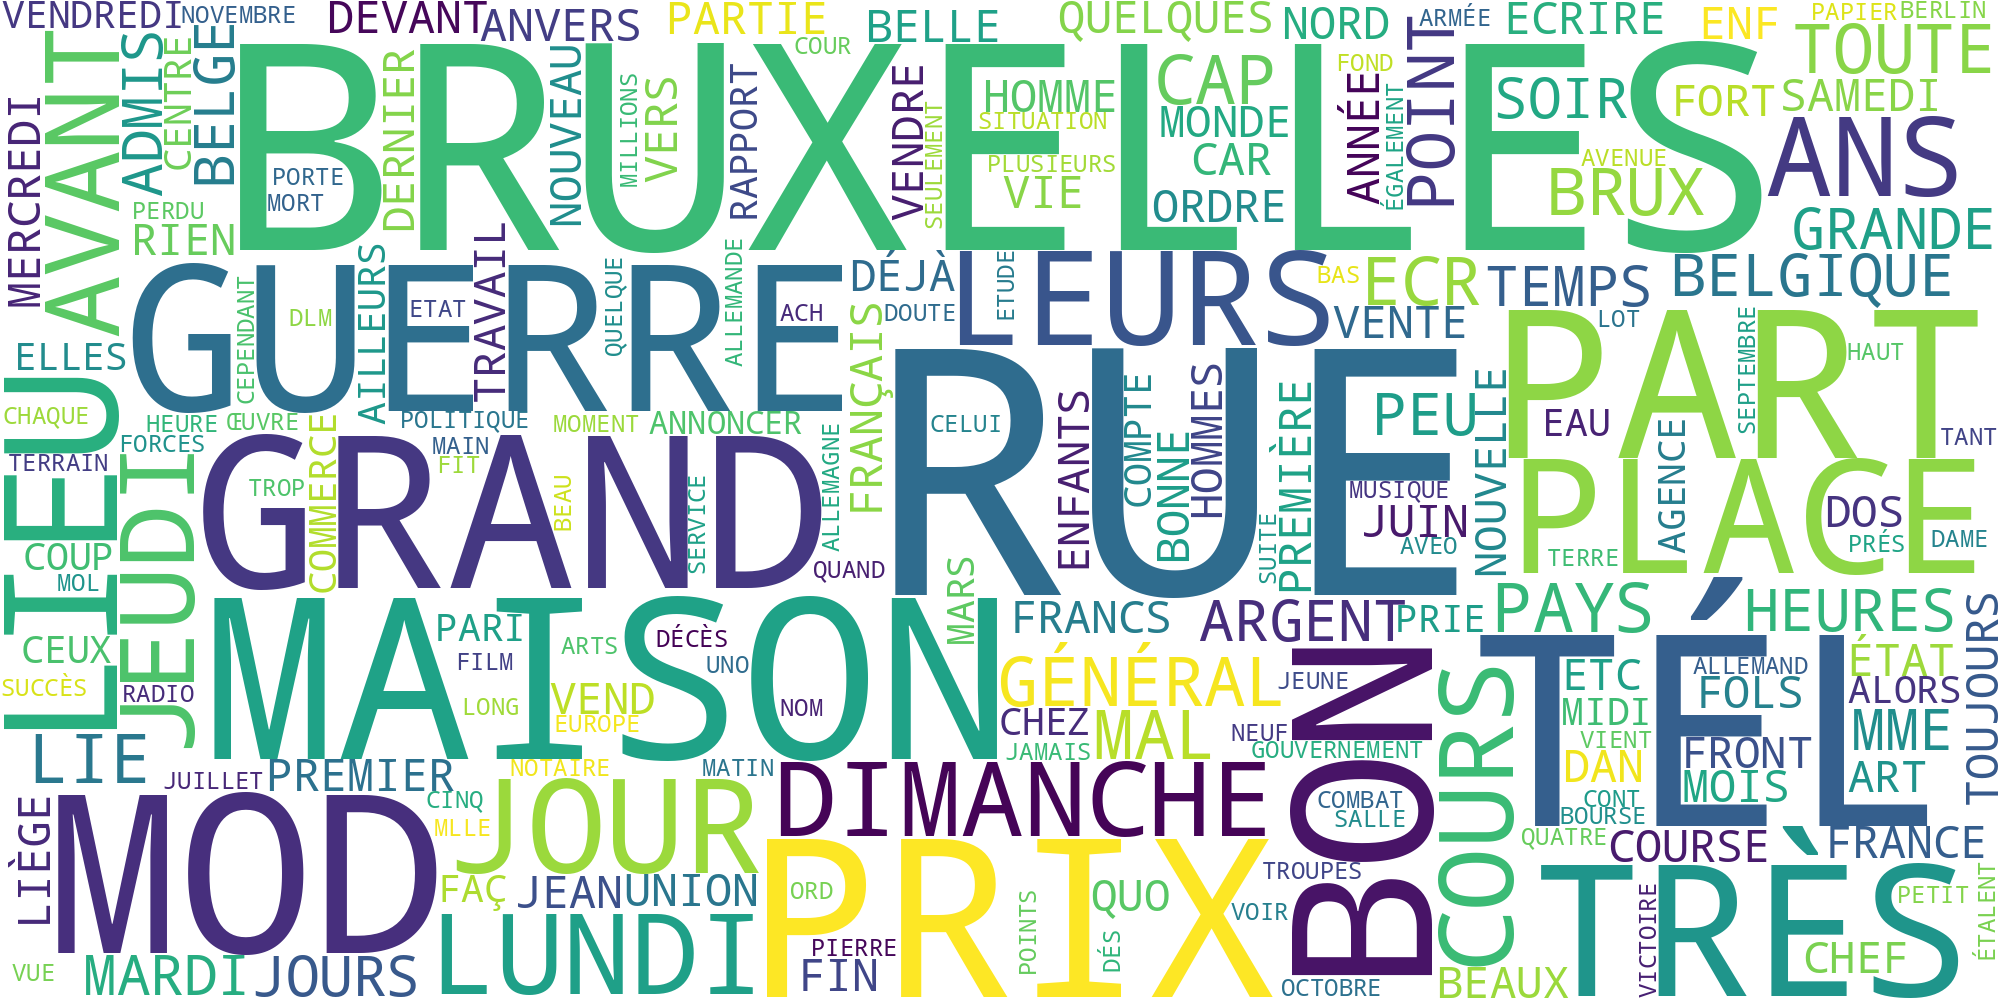

In [25]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

Deuxième itération

[('RUE', 2155), ('BRUXELLES', 1458), ('MAISON', 849), ('PRIX', 821), ('GRAND', 760), ('PART', 720), ('GUERRE', 704), ('BON', 645), ('TRÈS', 609), ('PLACE', 588)]
Occurrences conservées : 466182


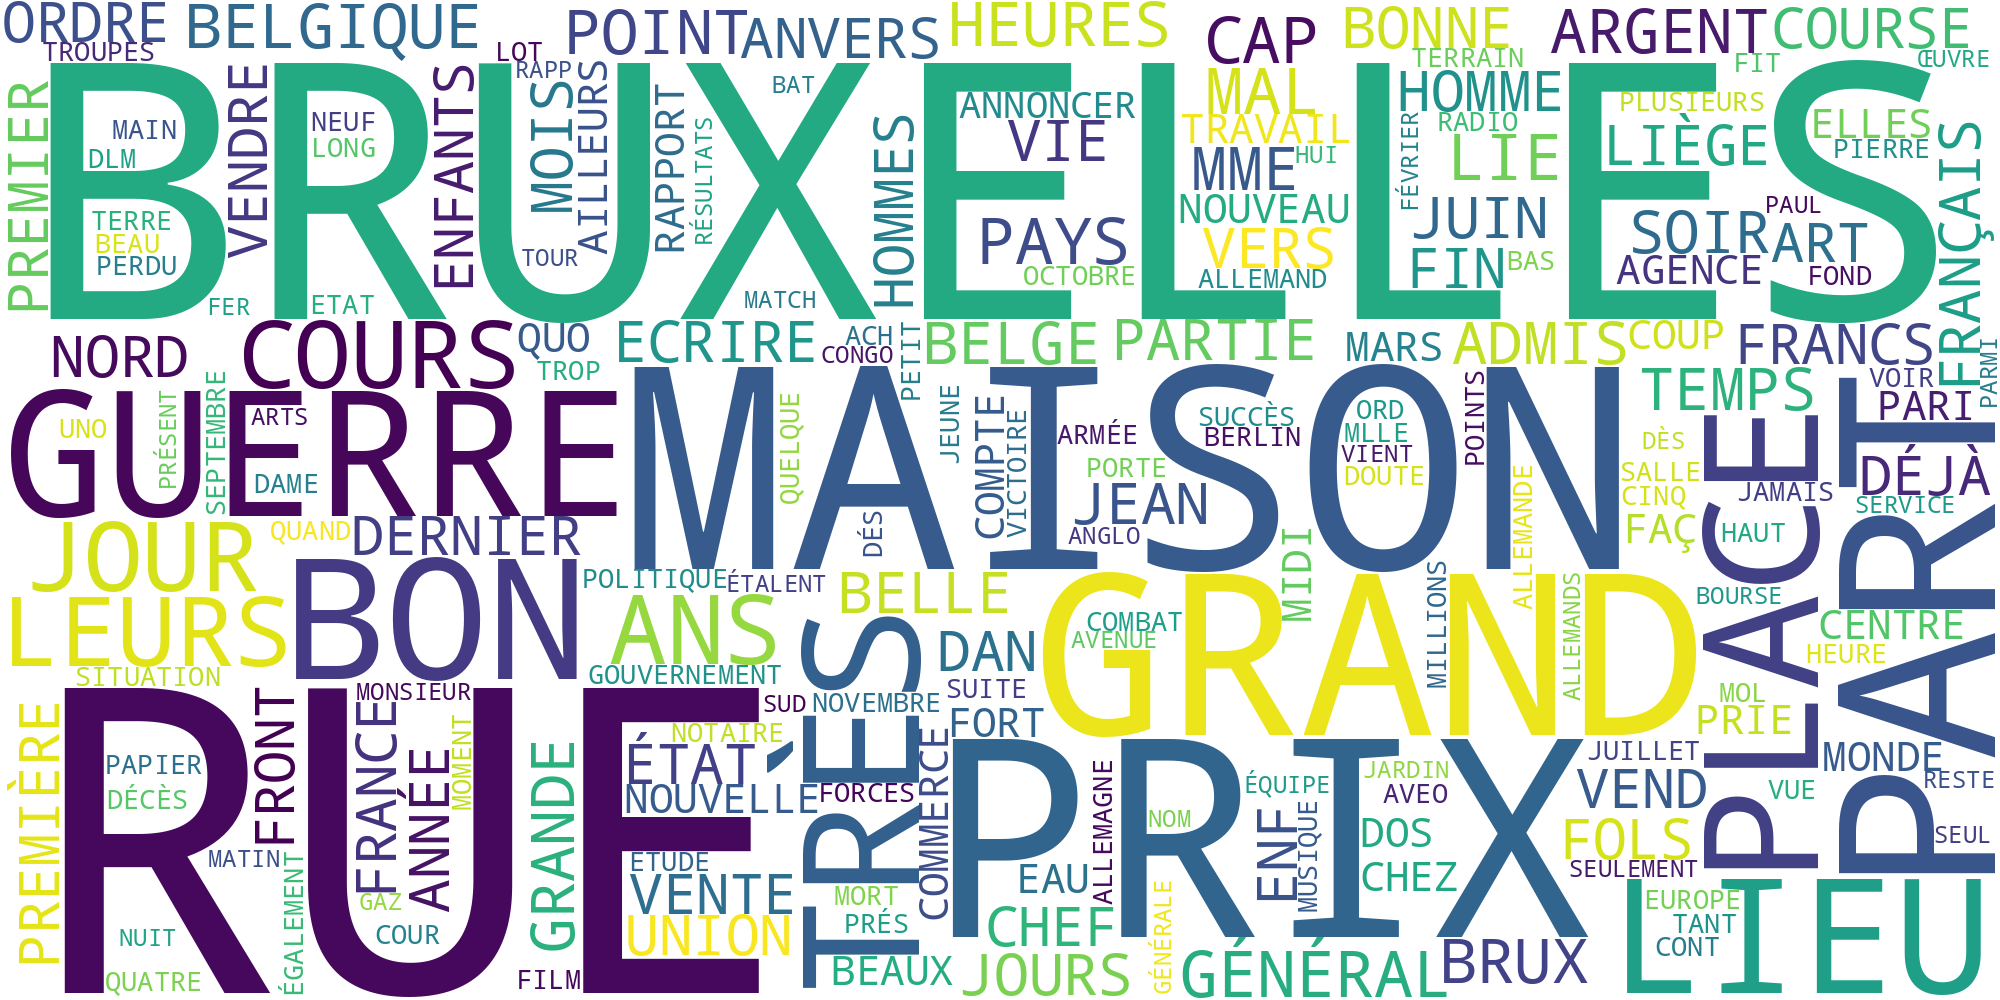

In [26]:
sw.update([
    "tél", "ecr", "écr", "écrire", "mod", "etc",
    "lundi", "mardi", "mercredi", "jeudi",
    "vendredi", "samedi", "dimanche",
    "celui", "ceux", "chaque", "quelques", "toute",
    "toujours", "peu", "alors", "avant", "devant",
    "rien", "car", "cependant",
    "isam", "dim", "janv"
])

# Refaire le nettoyage avec les nouveaux stopwords
clean_text(year, folder=temp_path)

# Lire le texte nettoyé
with open(os.path.join(temp_path, f'{year}_clean.txt'),
          'r', encoding='utf-8') as f:
    after = f.read()

# Recalculer les fréquences
frequencies = Counter(after.split())
print(frequencies.most_common(10))
print("Occurrences conservées :", sum(frequencies.values()))

# Enregistrer le deuxième nuage
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))



# Reconnaissance d'entités nommées avec SpaCy

La documentation est accessible ici: https://spacy.io/api

## Imports

In [27]:
from collections import defaultdict
import spacy
from spacy.lang.fr.examples import sentences

In [28]:
nlp = spacy.load('fr_core_news_md')

## Exemple sur un corpus de test fourni par SpaCy

In [29]:
# Imprimer le corpus de Spacy
sentences

['Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars',
 "Les voitures autonomes déplacent la responsabilité de l'assurance vers les constructeurs",
 "San Francisco envisage d'interdire les robots coursiers sur les trottoirs",
 'Londres est une grande ville du Royaume-Uni',
 'L’Italie choisit ArcelorMittal pour reprendre la plus grande aciérie d’Europe',
 "Apple lance HomePod parce qu'il se sent menacé par l'Echo d'Amazon",
 "La France ne devrait pas manquer d'électricité cet été, même en cas de canicule",
 'Nouvelles attaques de Trump contre le maire de Londres',
 'Où es-tu ?',
 'Qui est le président de la France ?',
 'Où est la capitale des États-Unis ?',
 'Quand est né Barack Obama ?']

In [30]:
# Isoler la première phrase
sent = sentences[0]
sent

'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars'

In [31]:
# Traiter la phrase avec Spacy
doc = nlp(sent)

In [32]:
type(doc)

spacy.tokens.doc.Doc

In [33]:
doc.text

'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars'

In [34]:
doc.to_json()

{'text': 'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars',
 'ents': [{'start': 0, 'end': 5, 'label': 'ORG'}],
 'sents': [{'start': 0, 'end': 72}],
 'tokens': [{'id': 0,
   'start': 0,
   'end': 5,
   'tag': 'PROPN',
   'pos': 'PROPN',
   'morph': 'Gender=Masc|Number=Sing',
   'lemma': 'Apple',
   'dep': 'nsubj',
   'head': 1},
  {'id': 1,
   'start': 6,
   'end': 13,
   'tag': 'VERB',
   'pos': 'VERB',
   'morph': 'Mood=Ind|Number=Sing|Person=3|Tense=Pres|VerbForm=Fin',
   'lemma': 'cherche',
   'dep': 'ROOT',
   'head': 1},
  {'id': 2,
   'start': 14,
   'end': 15,
   'tag': 'ADP',
   'pos': 'ADP',
   'morph': '',
   'lemma': 'à',
   'dep': 'mark',
   'head': 3},
  {'id': 3,
   'start': 16,
   'end': 23,
   'tag': 'VERB',
   'pos': 'VERB',
   'morph': 'VerbForm=Inf',
   'lemma': 'acheter',
   'dep': 'xcomp',
   'head': 1},
  {'id': 4,
   'start': 24,
   'end': 27,
   'tag': 'DET',
   'pos': 'DET',
   'morph': 'Definite=Ind|Gender=Fem|Number=Sing|PronType=Art'

In [35]:
# Appliquer le test sur toutes les phrases
for sent in sentences:
    doc = nlp(sent)
    entities = []
    for ent in doc.ents:
        entities.append(f"{ent.text} ({ent.label_})")
    if entities:
        print(f"'{doc.text}' contient les entités suivantes : {', '.join(entities)}")
    else:
        print(f"'{doc.text}' ne contient aucune entité")

'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars' contient les entités suivantes : Apple (ORG)
'Les voitures autonomes déplacent la responsabilité de l'assurance vers les constructeurs' ne contient aucune entité
'San Francisco envisage d'interdire les robots coursiers sur les trottoirs' contient les entités suivantes : San Francisco (LOC)
'Londres est une grande ville du Royaume-Uni' contient les entités suivantes : Londres (LOC), Royaume-Uni (LOC)
'L’Italie choisit ArcelorMittal pour reprendre la plus grande aciérie d’Europe' contient les entités suivantes : L’Italie (LOC), ArcelorMittal (ORG), Europe (LOC)
'Apple lance HomePod parce qu'il se sent menacé par l'Echo d'Amazon' contient les entités suivantes : Apple (ORG), HomePod (MISC), Echo (ORG), Amazon (ORG)
'La France ne devrait pas manquer d'électricité cet été, même en cas de canicule' contient les entités suivantes : La France (LOC)
'Nouvelles attaques de Trump contre le maire de Londres' contient les en

## Appliquer la reconnaissance d'entités nommées sur notre corpus

In [36]:
# Charger les textes de 1943
import os

year = 1943
data_path = "../../data/txt"
files = [f for f in os.listdir(data_path)
         if os.path.isfile(os.path.join(data_path, f)) and str(year) in f]

texts = []
for f in files:
    text = open(os.path.join(data_path, f), encoding='utf-8').read()
    texts.append(text)
len(texts)


100

In [37]:
%%time
# Traiter les textes

docs = []
for text in texts:
    doc = nlp(text)
    docs.append(doc)


CPU times: user 3min 30s, sys: 1.03 s, total: 3min 31s
Wall time: 3min 37s


In [38]:
# Compter les entités
people = defaultdict(int)
for doc in docs:
    for ent in doc.ents:
        if ent.label_ == "PER" and len(ent.text) > 3:
            people[ent.text] += 1


In [39]:
# Trier et imprimer

sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_people[:50]:
    print(f"{person} apparait {freq} fois dans le corpus")

Rossel apparait 472 fois dans le corpus
Soviets apparait 96 fois dans le corpus
Ecrire Ag apparait 77 fois dans le corpus
Louise apparait 68 fois dans le corpus
Cornélius apparait 67 fois dans le corpus
Jacques apparait 50 fois dans le corpus
Staline apparait 47 fois dans le corpus
Monsieur apparait 45 fois dans le corpus
défln apparait 43 fois dans le corpus
Belle-Rose apparait 42 fois dans le corpus
M. Churchill apparait 41 fois dans le corpus
Churchill apparait 38 fois dans le corpus
François apparait 37 fois dans le corpus
Roosevelt apparait 37 fois dans le corpus
culs apparait 35 fois dans le corpus
Duce apparait 33 fois dans le corpus
Brugmann apparait 31 fois dans le corpus
Louis apparait 30 fois dans le corpus
Rosa apparait 30 fois dans le corpus
Réun apparait 30 fois dans le corpus
Laval apparait 30 fois dans le corpus
E. P. apparait 30 fois dans le corpus
atel apparait 29 fois dans le corpus
g. Rossel apparait 29 fois dans le corpus
Lundi apparait 28 fois dans le corpus
SAVOY

Exercice: essayez de lister les lieux (LOC) et les organisations (ORG) les plus mentionnées dans le corpus

In [40]:
# Organisations
organisations = defaultdict(int)
for doc in docs:
    for ent in doc.ents:
        if ent.label_ == "ORG" and len(ent.text) > 3:
            organisations[ent.text] += 1

sorted_organisations = sorted(organisations.items(), key=lambda kv: kv[1], reverse=True)
for organisation, freq in sorted_organisations[:50]:
    print(f"{organisation} apparait {freq} fois dans le corpus")

# Lieux
places = defaultdict(int)
for doc in docs:
    for ent in doc.ents:
        if ent.label_ == "LOC" and len(ent.text) > 3:
            places[ent.text] += 1

sorted_places = sorted(places.items(), key=lambda kv: kv[1], reverse=True)
for place, freq in sorted_places[:50]:
    print(f"{place} apparait {freq} fois dans le corpus")


Inform apparait 98 fois dans le corpus
DIST apparait 76 fois dans le corpus
Reich apparait 67 fois dans le corpus
GALERIES apparait 67 fois dans le corpus
Standard apparait 51 fois dans le corpus
Union apparait 36 fois dans le corpus
Jeudi apparait 32 fois dans le corpus
Conseil apparait 28 fois dans le corpus
Reuter apparait 28 fois dans le corpus
Téléphone apparait 27 fois dans le corpus
PARC apparait 27 fois dans le corpus
ELYSEE apparait 27 fois dans le corpus
PALLADIUM apparait 26 fois dans le corpus
exlg apparait 25 fois dans le corpus
NÉCROLOGIE apparait 25 fois dans le corpus
Orchestre Radio apparait 25 fois dans le corpus
front de l’Est apparait 24 fois dans le corpus
Schaerb apparait 24 fois dans le corpus
FLORA apparait 24 fois dans le corpus
trav apparait 23 fois dans le corpus
Ford apparait 23 fois dans le corpus
SERVICES apparait 22 fois dans le corpus
BERGERE apparait 20 fois dans le corpus
GRILLON apparait 20 fois dans le corpus
Société apparait 20 fois dans le corpus
B

# Sentiment analysis 

## 1. Textblob-FR

Documentation: https://textblob.readthedocs.io/en/dev/

### Imports

In [41]:
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer

### Création d'une fonction `get_sentiment`

In [42]:
tb = Blobber(pos_tagger=PatternTagger(), analyzer=PatternAnalyzer())

def get_sentiment(input_text):
    blob = tb(input_text)
    polarity, subjectivity = blob.sentiment
    polarity_perc = f"{100*abs(polarity):.0f}"
    subjectivity_perc = f"{100*subjectivity:.0f}"
    if polarity > 0:
        polarity_str = f"{polarity_perc}% positive"
    elif polarity < 0:
        polarity_str = f"{polarity_perc}% negative"
    else:
        polarity_str = "neutral"
    if subjectivity > 0:
        subjectivity_str = f"{subjectivity_perc}% subjective"
    else:
        subjectivity_str = "perfectly objective"
    print(f"This text is {polarity_str} and {subjectivity_str}.")

### Analyser le sentiment d'une phrase

In [43]:
get_sentiment("Ce journal est vraiment super intéressant.")

This text is 65% positive and 75% subjective.


In [44]:
get_sentiment("Cette phrase est négative et je ne suis pas content !")

This text is 41% negative and 60% subjective.


TP2 : dix phrases de 1943

In [45]:
phrases = [
    ('KB_JB838_1943-02-09_01-00001.txt', 'Les experts se posent la question de savoir si le danger sous-marln atteint actuellement son point culminant.'),
    ('KB_JB838_1943-03-09_01-00001.txt', 'Par ailleurs, les Jeux de hasard, où de grosses sommes sont risquées, se développent comme une épidémie.'),
    ('KB_JB838_1943-03-10_01-00003.txt', "Le jeune homme fut Invité 4 expliquer au commissariat de police la provenance de cctto somme d'argent."),
    ('KB_JB838_1943-06-09_01-00001.txt', "L’été dernier, en qualité de ministre, de la Défense Nationale, J’ai entrepris un programme d'intensification des bombardements aériens."),
    ('KB_JB838_1943-08-28_01-00002.txt', 'Rien n’est fabriqué chez elle, ot chaque détail, chaquo scène porte son poids de souffrances et son relent de fatalité.'),
    ('KB_JB838_1943-09-06_01-00002.txt', "Je ne suis guère pessimiste, mats je pense, pour ma part, qu’on pourra s'estimer heureux si les prix se malnltennent généralement k leur niveau actuel."),
    ('KB_JB838_1943-10-06_01-00002.txt', 'Or, le besoin de cet aliment supplémentaire est considérable,, en temps do rationnement.'),
    ('KB_JB838_1943-10-16_01-00001.txt', "Rien qui ressemble ici au fastidieux pittoresque du carnet de notes avec ses accumulations de détails oii l'essentiel se dilue."),
    ('KB_JB838_1943-11-12_01-00001.txt', "A une autre époque et dans une autre guerre, on n'aurait même pas conçu la possibilité d’une ruse aussi machiavélique."),
    ('KB_JB838_1943-12-13_01-00001.txt', 'M. Brlcker, gouverneur de.l’Etat d’Ohio, a fait savoir qu’il po3ait sa candidature aux prochaines élections présidentielles.'),
]


In [46]:
rows = []
for fichier, phrase in phrases:
    blob = tb(phrase)
    polarity, subjectivity = blob.sentiment
    rows.append([fichier, phrase, polarity, subjectivity])


In [47]:
import pandas as pd

tableau = pd.DataFrame(rows, columns=["fichier", "phrase", "polarite", "subjectivite"])
tableau.to_csv("sentiments_1943.csv", index=False)
tableau


,fichier,phrase,polarite,subjectivite
0,KB_JB838_1943-02-09_01-00001.txt,Les experts se posent la question de savoir si...,0.100000,0.600000
1,KB_JB838_1943-03-09_01-00001.txt,"Par ailleurs, les Jeux de hasard, où de grosse...",0.000000,0.200000
2,KB_JB838_1943-03-10_01-00003.txt,Le jeune homme fut Invité 4 expliquer au commi...,0.320000,0.400000
3,KB_JB838_1943-06-09_01-00001.txt,"L’été dernier, en qualité de ministre, de la D...",0.027500,0.050000
4,KB_JB838_1943-08-28_01-00002.txt,"Rien n’est fabriqué chez elle, ot chaque détai...",0.000000,0.000000
5,KB_JB838_1943-09-06_01-00002.txt,"Je ne suis guère pessimiste, mats je pense, po...",0.200000,0.375000
6,KB_JB838_1943-10-06_01-00002.txt,"Or, le besoin de cet aliment supplémentaire es...",0.100000,0.200000
7,KB_JB838_1943-10-16_01-00001.txt,Rien qui ressemble ici au fastidieux pittoresq...,0.300000,0.300000
8,KB_JB838_1943-11-12_01-00001.txt,"A une autre époque et dans une autre guerre, o...",-0.066667,0.166667
9,KB_JB838_1943-12-13_01-00001.txt,"M. Brlcker, gouverneur de.l’Etat d’Ohio, a fai...",0.000000,0.000000
